<a href="https://colab.research.google.com/github/Maryam-Yaqoob/Hunarmand-Punjab-Machine-Learning-and-Data-Science/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Customer Churn Prediction and Classification System

**Dataset:** the notebook downloads the Kaggle *Telco Customer Churn* dataset (`blastchar/telco-customer-churn`) with `kagglehub`. If the download fails it looks for the local CSV, and finally falls back to a synthetic dataset (with missing values, duplicates, infinite values and inconsistent text) so it always runs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import warnings; warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

---
## A. Data Investigation and Preprocessing

### A1. Load the dataset and display dimensions, data types and statistical summary

In [2]:
KAGGLE_DATASET = "blastchar/telco-customer-churn"   # Kaggle "Telco Customer Churn"
LOCAL_CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"  # used if Kaggle download fails
TARGET = "Churn"

def make_synthetic(n=1500, seed=42):
    rng = np.random.default_rng(seed)
    tenure = rng.integers(1, 72, n)
    monthly = rng.normal(65, 25, n).clip(18, 120).round(2)
    contract = rng.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.25, 0.2])
    internet = rng.choice(["DSL", "Fiber optic", "No"], n, p=[0.35, 0.45, 0.2])
    payment = rng.choice(["Electronic check", "Mailed check", "Credit card", "Bank transfer"], n)
    gender = rng.choice(["Male", "Female"], n)
    support = rng.integers(0, 8, n)
    logit = (-1.0 + 0.02*(monthly-65) - 0.04*tenure + 1.2*(contract == "Month-to-month")
             + 0.5*(internet == "Fiber optic") + 0.15*support)
    churn = np.where(rng.random(n) < 1/(1+np.exp(-logit)), "Yes", "No")
    df = pd.DataFrame(dict(customerID=[f"C{i:05d}" for i in range(n)], gender=gender,
        tenure=tenure.astype(float), MonthlyCharges=monthly, SupportCalls=support,
        Contract=contract, InternetService=internet, PaymentMethod=payment, Churn=churn))
    df["TotalCharges"] = df["tenure"] * df["MonthlyCharges"]
    # --- inject data problems ---
    for c in ["tenure", "MonthlyCharges", "Contract", "InternetService"]:
        df.loc[rng.choice(n, 40, replace=False), c] = np.nan
    df.loc[rng.choice(n, 5, replace=False), "TotalCharges"] = np.inf
    df.loc[rng.choice(n, 3, replace=False), "TotalCharges"] = -np.inf
    df.loc[rng.choice(n, 30, replace=False), "Contract"] = "  month-to-month "   # inconsistent text
    df.loc[rng.choice(n, 20, replace=False), "gender"] = "MALE"
    df = pd.concat([df, df.sample(40, random_state=1)], ignore_index=True)       # duplicates
    return df

def load_data():
    """1) Kaggle download  2) local CSV  3) synthetic fallback"""
    try:
        import subprocess, sys, glob
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=False)
        import kagglehub
        folder = kagglehub.dataset_download(KAGGLE_DATASET)
        csv_file = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)[0]
        print("Downloaded from Kaggle:", csv_file)
        return pd.read_csv(csv_file)
    except Exception as e:
        print("Kaggle download failed:", repr(e)[:150])
    if os.path.exists(LOCAL_CSV):
        print("Using local file:", LOCAL_CSV)
        return pd.read_csv(LOCAL_CSV)
    print("Using synthetic dataset (for demo only)")
    return make_synthetic()

df = load_data()

# Telco data stores TotalCharges as text (blank for new customers) -> make it numeric
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Dimensions:", df.shape)
print("\nData types:\n", df.dtypes)
display(df.head())
df.describe(include="all").T

100%|██████████| 172k/172k [00:00<00:00, 40.2MB/s]

Extracting files...
Downloaded from Kaggle: /root/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1/WA_Fn-UseC_-Telco-Customer-Churn.csv
Dimensions: (7043, 21)

Data types:
 customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### A2. Identify and handle missing values, duplicates and infinite values

In [3]:
num_all = df.select_dtypes(include=np.number).columns
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("Infinite values:\n", pd.Series({c: int(np.isinf(df[c]).sum()) for c in num_all}).loc[lambda s: s > 0])

Missing values:
 TotalCharges    11
dtype: int64

Duplicate rows: 0
Infinite values:
 Series([], dtype: int64)


In [4]:
# 1) Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# 2) Fix inconsistent text in categorical columns (whitespace / letter case)
for c in df.select_dtypes(exclude=np.number).columns:
    s = df[c].astype("string").str.strip().str.lower()
    df[c] = s.astype(object).where(s.notna() & (s != ""), np.nan)

# 3) Replace infinite values with NaN (they are imputed later, inside the pipeline)
df = df.replace([np.inf, -np.inf], np.nan)

# 4) Drop rows with no target label (cannot be used for supervised learning)
df = df.dropna(subset=[TARGET])

# 5) Drop identifier columns (no predictive value)
id_cols = [c for c in df.columns if "id" == c.lower()[-2:] and df[c].nunique() == len(df)]
df = df.drop(columns=id_cols)
print("Dropped ID columns:", id_cols)
print("Shape after cleaning:", df.shape)
print("Remaining missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

Dropped ID columns: ['customerID']
Shape after cleaning: (7043, 20)
Remaining missing values:
 TotalCharges    11
dtype: int64


Missing values and the remaining NaNs from infinite values are **imputed inside the preprocessing pipeline** (median for numeric, most-frequent for categorical), so statistics come from training data only.

### A3. Separate numerical and categorical features

In [5]:
# Encode target: yes -> 1, no -> 0
df[TARGET] = df[TARGET].astype(str).str.lower().map({"yes": 1, "no": 0, "1": 1, "0": 0, "true": 1, "false": 0})
df = df.dropna(subset=[TARGET]); df[TARGET] = df[TARGET].astype(int)

X = df.drop(columns=[TARGET])
y = df[TARGET]
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical:", num_features)
print("Categorical:", cat_features)
print("\nChurn distribution:\n", y.value_counts(normalize=True).round(3))

Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Churn distribution:
 Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


### A4. Encoding and scaling strategy
Numeric: median imputation + `StandardScaler`. Categorical: most-frequent imputation + `OneHotEncoder`. Defined as a `ColumnTransformer` (fitted later on training data only).

In [6]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

---
## B. Feature Engineering and Data Splitting

### B1. Select input features and target

In [7]:
print("Input features:", X.columns.tolist())
print("Target column :", TARGET)

Input features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Target column : Churn


### B2. 80:20 train-test split (stratified)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

### B3. Fit preprocessing on training data only (no data leakage)

In [9]:
X_train_p = preprocessor.fit_transform(X_train)   # fit + transform on TRAIN
X_test_p = preprocessor.transform(X_test)         # transform only on TEST

### B4. Final shapes

In [10]:
print("X_train:", X_train_p.shape, " y_train:", y_train.shape)
print("X_test :", X_test_p.shape, " y_test :", y_test.shape)

X_train: (5634, 45)  y_train: (5634,)
X_test : (1409, 45)  y_test : (1409,)


---
## C. Model Implementation

### C1–C3. Logistic Regression and KNN: train and predict on unseen test data

In [11]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_p, y_train)
y_pred_lr = log_reg.predict(X_test_p)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_p, y_train)
y_pred_knn = knn.predict(X_test_p)
print("Both models trained and predictions generated.")

Both models trained and predictions generated.


### C4. Experiment with different K values for KNN

,K,Accuracy,Precision,Recall,F1
0,3,0.7537,0.5349,0.5535,0.5440
1,5,0.7637,0.5527,0.5749,0.5636
2,7,0.7651,0.5556,0.5749,0.5650
3,11,0.7786,0.5838,0.5775,0.5806
4,15,0.7779,0.5845,0.5642,0.5741
5,21,0.7814,0.5907,0.5749,0.5827


Best K (by F1): 21


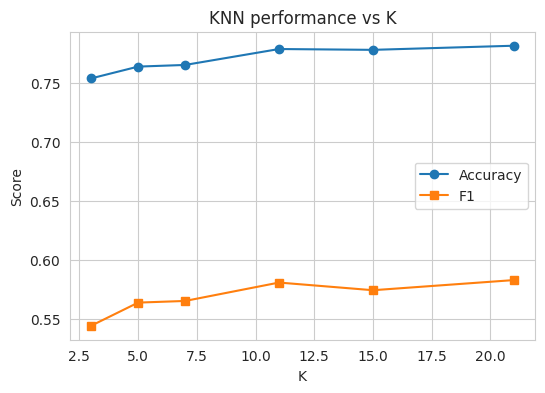

In [12]:
k_values = [3, 5, 7, 11, 15, 21]
rows = []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_p, y_train)
    p = m.predict(X_test_p)
    rows.append({"K": k, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p, zero_division=0),
                 "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
k_results = pd.DataFrame(rows).round(4)
display(k_results)

best_k = int(k_results.sort_values("F1", ascending=False).iloc[0]["K"])
print("Best K (by F1):", best_k)
plt.figure(figsize=(6, 4))
plt.plot(k_results["K"], k_results["Accuracy"], marker="o", label="Accuracy")
plt.plot(k_results["K"], k_results["F1"], marker="s", label="F1")
plt.xlabel("K"); plt.ylabel("Score"); plt.title("KNN performance vs K"); plt.legend(); plt.show()

knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_p, y_train)   # final KNN
y_pred_knn = knn.predict(X_test_p)

---
## D. Model Evaluation and Comparison

### D1. Accuracy, Precision, Recall and F1-score

In [13]:
def metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred),
            "F1-score": f1_score(y_true, y_pred)}

comparison = pd.DataFrame({"Logistic Regression": metrics(y_test, y_pred_lr),
                           f"KNN (K={best_k})": metrics(y_test, y_pred_knn)}).T.round(4)

### D2. Confusion matrices

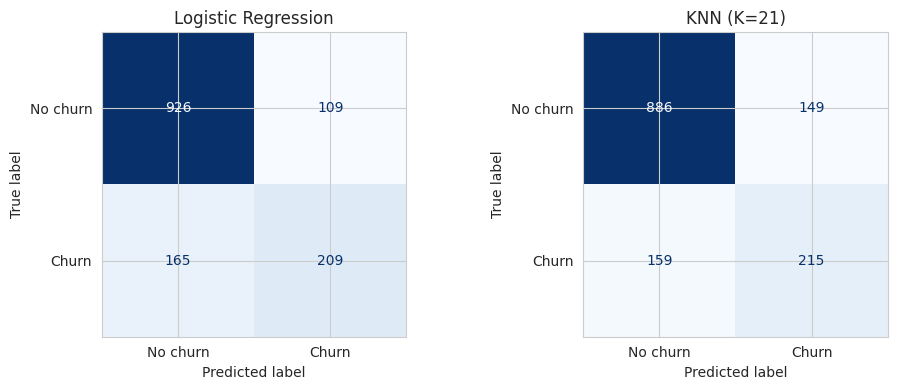

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, pred) in zip(ax, [("Logistic Regression", y_pred_lr), (f"KNN (K={best_k})", y_pred_knn)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No churn", "Churn"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()

### D3. Comparison table and better-performing model

In [15]:
display(comparison)
best_model = comparison["F1-score"].idxmax()
print(f"Better-performing model (by F1-score, which balances precision and recall on imbalanced churn data): {best_model}")

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.8055,0.6572,0.5588,0.6040
KNN (K=21),0.7814,0.5907,0.5749,0.5827


Better-performing model (by F1-score, which balances precision and recall on imbalanced churn data): Logistic Regression


---
## E. Practical Visualization

### E1. Comparison of both models' evaluation results

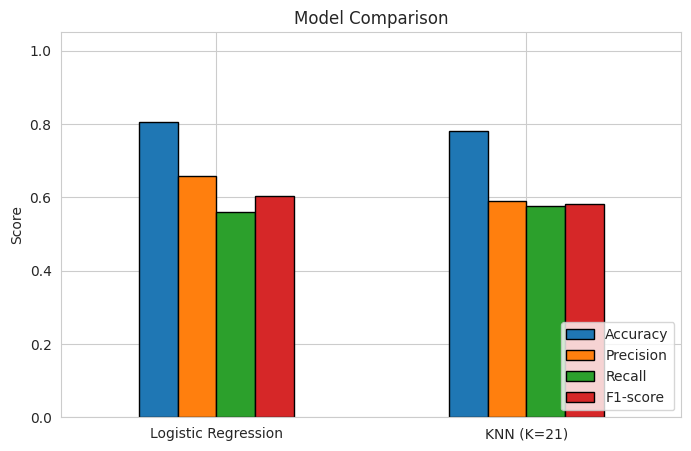

In [16]:
comparison.plot(kind="bar", figsize=(8, 5), rot=0, edgecolor="k")
plt.title("Model Comparison"); plt.ylabel("Score"); plt.ylim(0, 1.05); plt.legend(loc="lower right")
plt.show()

### E2. Actual vs predicted churn labels (10+ test samples)

In [17]:
label = {0: "No", 1: "Yes"}
best_pred = y_pred_lr if "Logistic" in best_model else y_pred_knn
samples = pd.DataFrame({"Actual": y_test.values[:15], "LogReg Pred": y_pred_lr[:15], "KNN Pred": y_pred_knn[:15]}).replace(label)
samples["LogReg Correct"] = samples["Actual"] == samples["LogReg Pred"]
samples["KNN Correct"] = samples["Actual"] == samples["KNN Pred"]
samples

,Actual,LogReg Pred,KNN Pred,LogReg Correct,KNN Correct
0,No,No,No,True,True
1,No,Yes,Yes,False,False
2,No,No,No,True,True
3,No,No,No,True,True
4,No,No,No,True,True
5,No,Yes,Yes,False,False
6,No,No,No,True,True
7,No,No,No,True,True
8,No,No,No,True,True
9,Yes,No,No,False,False


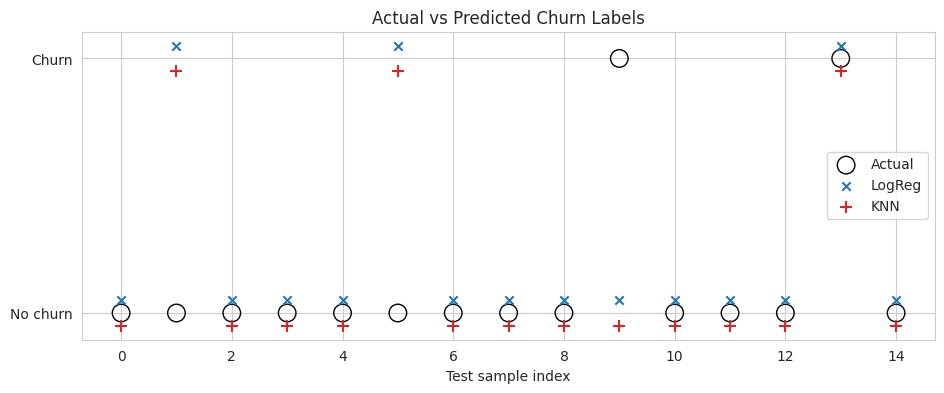

In [18]:
n = 15
x = np.arange(n)
plt.figure(figsize=(11, 4))
plt.scatter(x, y_test.values[:n], s=160, facecolors="none", edgecolors="k", label="Actual")
plt.scatter(x, y_pred_lr[:n] + 0.05, marker="x", c="tab:blue", label="LogReg")
plt.scatter(x, y_pred_knn[:n] - 0.05, marker="+", c="tab:red", s=80, label="KNN")
plt.yticks([0, 1], ["No churn", "Churn"]); plt.xlabel("Test sample index")
plt.title("Actual vs Predicted Churn Labels"); plt.legend(); plt.show()